--- Пропуски до обработки ---
Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64

--- Проверка типов данных ---
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object

--- Пропуски после обработки ---
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64

--- Корреляционная матрица ---
          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00

--- Коррел

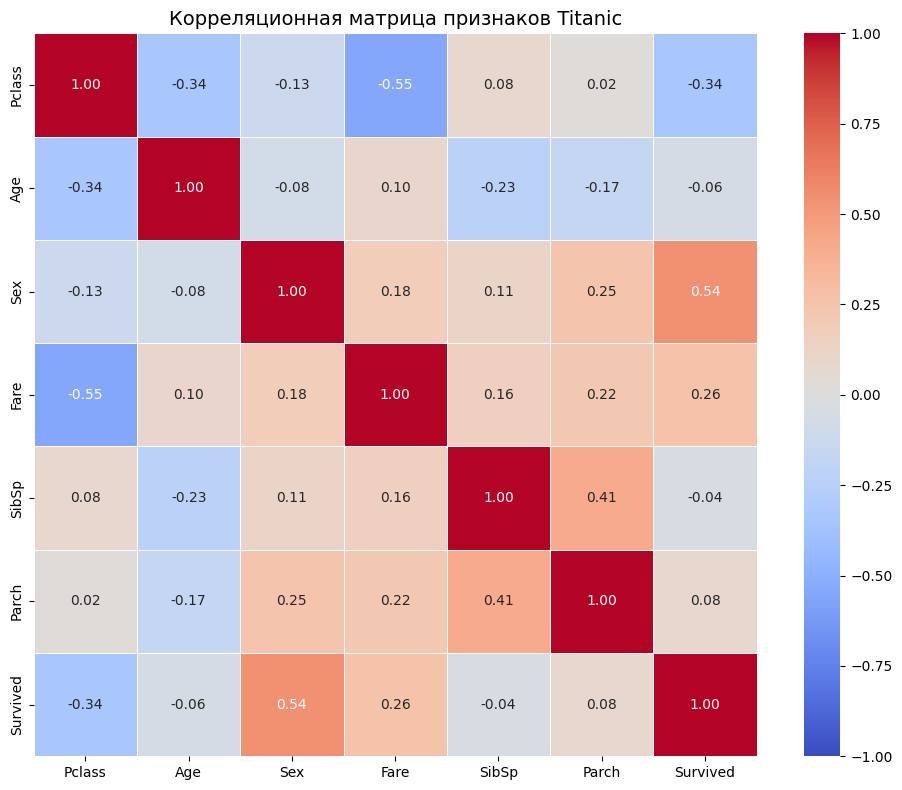

In [9]:
# 1. Загрузка необходимых библиотек
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Загрузка файла titanic.csv
# Если файл лежит в другой папке, укажите полный путь, например: 'C:/data/titanic.csv'
df = pd.read_csv('/content/titanic (1).csv')

# 3-4. Выбор признаков и целевой переменной
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

# Создаем копию таблицы только с нужными столбцами, чтобы не менять исходный df
data = df[features + [target]].copy()

# 5. Проверка наличия пропущенных значений (до обработки)
print("--- Пропуски до обработки ---")
print(data.isnull().sum())

# 6. Обработка пропусков в Age (заполняем медианой)
data['Age'] = data['Age'].fillna(data['Age'].median())

# 7. Преобразование Sex из текстового значения в числовое
# male -> 0, female -> 1
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

# Проверка подготовки данных
print("\n--- Проверка типов данных ---")
print(data.dtypes)
print("\n--- Пропуски после обработки ---")
print(data.isnull().sum())

# ==========================================
# Расчёт корреляционной матрицы
# ==========================================
corr_matrix = data.corr()
corr_rounded = corr_matrix.round(2)

print("\n--- Корреляционная матрица ---")
print(corr_rounded)

# Анализ корреляции с Survived (исключая саму себя)
survived_corr = corr_rounded['Survived'].drop('Survived')

print("\n--- Корреляция признаков с Survived ---")
print(survived_corr)

# Находим признаки с самой сильной положительной и отрицательной связью
max_pos_feature = survived_corr.idxmax()
max_pos_value = survived_corr.max()
max_neg_feature = survived_corr.idxmin()
max_neg_value = survived_corr.min()

print(f"\nНаиболее сильная ПОЛОЖИТЕЛЬНАЯ корреляция: {max_pos_feature} ({max_pos_value})")
print(f"Наиболее сильная ОТРИЦАТЕЛЬНАЯ корреляция: {max_neg_feature} ({max_neg_value})")

# ==========================================
# Построение тепловой карты (heatmap)
# ==========================================
plt.figure(figsize=(10, 8)) # Задаем подходящий размер изображения

# Строим heatmap с помощью seaborn
sns.heatmap(
    corr_rounded,      # какие данные передать
    annot=True,        # параметр для вывода значений коэффициентов внутри ячеек
    cmap='coolwarm',   # параметр, отвечающий за цветовую палитру
    fmt='.2f',         # формат вывода чисел (2 знака после запятой)
    vmin=-1,           # минимальное значение для цветовой шкалы
    vmax=1,            # максимальное значение для цветовой шкалы
    square=True,       # чтобы ячейки были квадратными
    linewidths=0.5     # линии между ячейками
)

plt.title('Корреляционная матрица признаков Titanic', fontsize=14)
plt.tight_layout() # Чтобы подписи не обрезались
plt.show()